# 09. 최종 Test 평가(E08)

- **모델**: 후보 A, 곧 Full FT(ImageNet 가중치에서 전체 학습), letterbox 224, 증강 없음입니다(D-031). 가중치는 `models/SEL-A-s43_full.pt`(seed 43)입니다.
- **평가는 한 번만 했습니다.** `scripts/run_e08_test.py`가 가중치 SHA를 확인한 뒤 Test를 예측하고 `experiments/E08/`에 저장했습니다. 이 노트북은 그 파일만 읽고 모델을 다시 실행하지 않습니다.
- **Test 결과를 보고 바꾸지 않습니다.** 모델, 가중치, 전처리, 지표 모두 그대로 둡니다(`experiments/E08/PLAN.md`). 아래 오류 분석은 "어디서 일반화가 깨졌는가"를 적는 데까지만 하고, 그 결과로 다시 고르지 않습니다.
- Test는 Train·Val과 겹치지 않는 3명(Z24·Z59·Z83)입니다. 운동마다 한 사람이 맡았습니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 200)
NAMES = class_names()
E08 = ROOT / "experiments" / "E08"
T = json.loads((E08 / "test_summary.json").read_text(encoding="utf-8"))
V = json.loads((ROOT / "experiments" / "SEL-A-s43" / "full" / "summary.json").read_text(encoding="utf-8"))["val"]
P = pd.read_csv(E08 / "pred_test.csv")
print("평가 시각:", T["evaluated_at"], "| 가중치 SHA-256:", T["weights_sha256"][:16], "…")
print("Test 이미지:", T["n_images"], "| 사람:", T["persons"])
pd.DataFrame({"Val(Z23·Z62·Z89)": [V["macro_f1"], V["accuracy"]], "Test(Z24·Z59·Z83)": [T["macro_f1"], T["accuracy"]]},
             index=["Macro F1", "Accuracy"]).assign(차이=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4)

font: Malgun Gothic
평가 시각: 2026-11-26 15:12:41 | 가중치 SHA-256: f21a180db8c362ef …
Test 이미지: 1432 | 사람: ['Z24', 'Z59', 'Z83']


,Val(Z23·Z62·Z89),Test(Z24·Z59·Z83),차이
Macro F1,0.8782,0.8386,-0.0396
Accuracy,0.8868,0.8631,-0.0237


## 1. 클래스별 Val vs Test

In [2]:
order = [c for g in GROUPS.values() for c in g]
grp = {c: k for k, g in GROUPS.items() for c in g}
who = P.groupby("target_id")["person_id"].first()
rows = []
for c in order:
    n = NAMES[c]
    rows.append({"클래스": f"{c} {n}", "묶음": grp[c], "Test 사람": who[c], "Test 장수": T["per_class"]["support"][n],
                 "Val Recall": V["per_class"]["recall"][n], "Test Recall": T["per_class"]["recall"][n],
                 "Val F1": V["per_class"]["f1"][n], "Test F1": T["per_class"]["f1"][n]})
cls = pd.DataFrame(rows).set_index("클래스")
cls["F1 차이"] = cls["Test F1"] - cls["Val F1"]
cls["Macro F1 기여"] = cls["F1 차이"] / 12   # 이 클래스가 Macro F1 차이에 보탠 몫
display(cls.round(3))
print(f"Macro F1 차이 합계 {cls['Macro F1 기여'].sum():+.4f} 중 바벨 로우 {cls.loc['9 바벨 로우', 'Macro F1 기여']:+.4f}, "
      f"덤벨 로우 {cls.loc['2 덤벨 벤트오버 로우', 'Macro F1 기여']:+.4f}")

,묶음,Test 사람,Test 장수,Val Recall,Test Recall,Val F1,Test F1,F1 차이,Macro F1 기여
클래스,,,,,,,,,
0 Y - Exercise,맨몸(바닥),Z59,64,0.969,0.984,0.976,0.940,-0.036,-0.003
1 니푸쉬업,맨몸(바닥),Z59,160,1.000,1.000,1.000,1.000,0.000,0.000
4 라잉 레그 레이즈,맨몸(바닥),Z59,128,0.953,0.977,0.946,0.951,0.005,0.000
10 바이시클 크런치,맨몸(바닥),Z59,64,0.891,0.781,0.898,0.870,-0.028,-0.002
2 덤벨 벤트오버 로우,바벨·덤벨(선 자세),Z24,160,0.775,0.725,0.763,0.672,-0.091,-0.008
7 바벨 데드리프트,바벨·덤벨(선 자세),Z24,160,0.594,0.631,0.640,0.610,-0.029,-0.002
8 바벨 런지,바벨·덤벨(선 자세),Z24,160,0.938,0.919,0.929,0.955,0.026,0.002
9 바벨 로우,바벨·덤벨(선 자세),Z24,64,0.484,0.094,0.434,0.115,-0.318,-0.027
3 딥스,기구,Z83,128,1.000,1.000,1.000,1.000,0.000,0.000


Macro F1 차이 합계 -0.0396 중 바벨 로우 -0.0265, 덤벨 로우 -0.0076


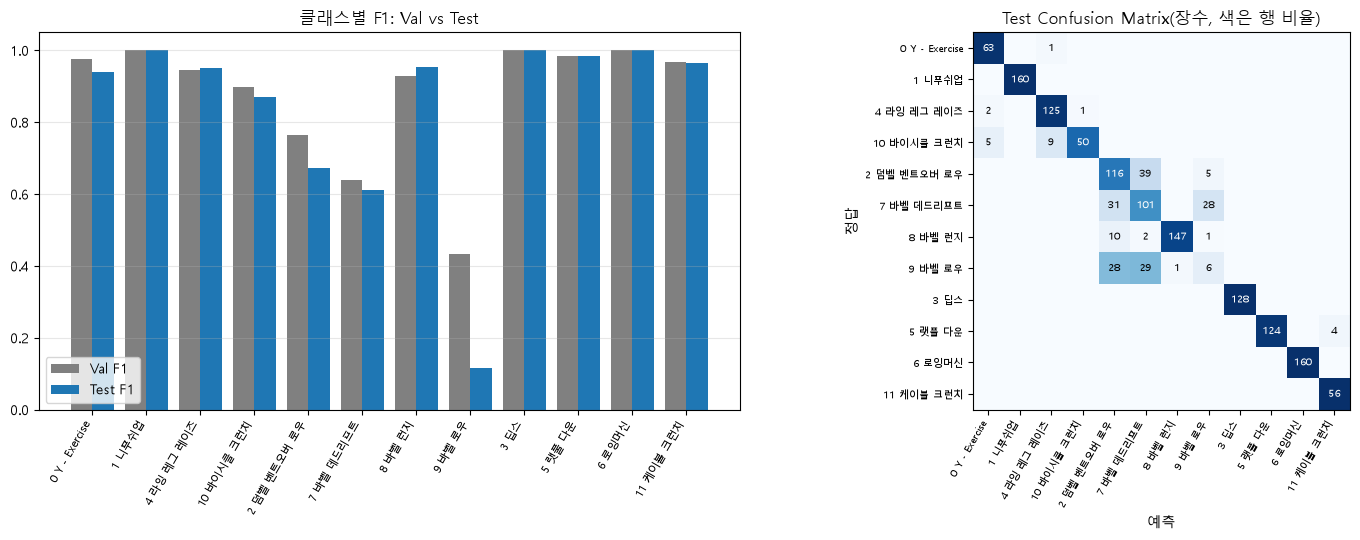

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
x = np.arange(len(order))
axes[0].bar(x - 0.2, cls["Val F1"], 0.4, label="Val F1", color="gray")
axes[0].bar(x + 0.2, cls["Test F1"], 0.4, label="Test F1", color="C0")
axes[0].set_xticks(x); axes[0].set_xticklabels(cls.index, rotation=60, ha="right", fontsize=8)
axes[0].set_ylim(0, 1.05); axes[0].legend(loc="lower left"); axes[0].grid(alpha=.3, axis="y"); axes[0].set_title("클래스별 F1: Val vs Test")
cm = np.array(T["confusion_matrix"])[np.ix_(order, order)]
cmn = cm / cm.sum(1, keepdims=True)
axes[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(len(order)):
    for j in range(len(order)):
        if cm[i, j]:
            axes[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="w" if cmn[i, j] > .5 else "k")
lab = [f"{c} {NAMES[c]}" for c in order]
axes[1].set_xticks(range(len(order))); axes[1].set_xticklabels(lab, rotation=60, ha="right", fontsize=7)
axes[1].set_yticks(range(len(order))); axes[1].set_yticklabels(lab, fontsize=7)
axes[1].set_xlabel("예측"); axes[1].set_ylabel("정답"); axes[1].set_title("Test Confusion Matrix(장수, 색은 행 비율)")
plt.tight_layout(); plt.savefig(FIGURES / "e08_test.png", dpi=110); plt.show()

## 2. 오답은 어디에 있는가

In [4]:
W = P[~P["correct"]]
same = (W["target_id"].map(grp) == W["pred"].map(grp))
print(f"오답 {len(W)}장 중 같은 묶음 안의 오답 {same.sum()}장({same.mean():.1%})")
print("정답일 때 평균 확신도", round(P[P.correct]['conf'].mean(), 3), "/ 오답일 때", round(W['conf'].mean(), 3))
W.groupby(["true_name", "pred_name"]).size().rename("장수").sort_values(ascending=False).to_frame()

오답 196장 중 같은 묶음 안의 오답 196장(100.0%)
정답일 때 평균 확신도 0.973 / 오답일 때 0.766


,,장수
true_name,pred_name,
덤벨 벤트오버 로우,바벨 데드리프트,39
바벨 데드리프트,덤벨 벤트오버 로우,31
바벨 로우,바벨 데드리프트,29
바벨 데드리프트,바벨 로우,28
바벨 로우,덤벨 벤트오버 로우,28
바벨 런지,덤벨 벤트오버 로우,10
바이시클 크런치,라잉 레그 레이즈,9
덤벨 벤트오버 로우,바벨 로우,5
바이시클 크런치,Y - Exercise,5


In [5]:
g = P[P["target_id"].isin([2, 7, 9])]
print("바벨·덤벨 묶음(Test는 모두 Z24): 클래스 × 카메라 정답률(괄호 안은 장수). A·B 뒤, C 정면, D·E 옆(E06)")
t = g.groupby(["true_name", "camera"])["correct"].agg(["mean", "size"])
t.apply(lambda r: f"{r['mean']:.2f} ({int(r['size'])})", axis=1).unstack()

바벨·덤벨 묶음(Test는 모두 Z24): 클래스 × 카메라 정답률(괄호 안은 장수). A·B 뒤, C 정면, D·E 옆(E06)


camera,A,B,C,D,E
true_name,,,,,
덤벨 벤트오버 로우,0.03 (33),0.82 (34),1.00 (31),1.00 (29),0.82 (33)
바벨 데드리프트,0.13 (30),0.88 (34),0.97 (32),0.18 (33),0.97 (31)
바벨 로우,0.55 (11),0.00 (13),0.00 (15),0.00 (13),0.00 (12)


In [6]:
clip = g.groupby(["true_name", "clip_id"])["correct"].mean()
print("클립(8장)별 정답률 분포: 클립 전체를 놓쳤는가, 일부 프레임만 놓쳤는가")
clip.groupby(level=0).describe()[["count", "min", "50%", "max"]].round(2)

클립(8장)별 정답률 분포: 클립 전체를 놓쳤는가, 일부 프레임만 놓쳤는가


,count,min,50%,max
true_name,,,,
덤벨 벤트오버 로우,20.0,0.5,0.75,0.88
바벨 데드리프트,20.0,0.5,0.62,0.75
바벨 로우,8.0,0.0,0.12,0.12


## 3. 해석

### 3.1 최종 결과

| 지표 | Val(Z23·Z62·Z89, 선정에 쓴 값) | Test(Z24·Z59·Z83, 1회) | 차이 |
|---|---|---|---|
| Macro F1 | 0.878 | **0.839** | −0.040 |
| Accuracy | 0.887 | **0.863** | −0.024 |

- 이 프로젝트의 최종 성능은 **Test Macro F1 0.839, Accuracy 0.863**입니다. 결과를 보고 바꾼 것은 없습니다.
- Test가 Val보다 0.04 낮습니다. 선정에 쓴 Val 점수는 낙관적이었습니다. 원인은 두 가지가 겹친 것으로 봅니다.
  1. Val도 Test도 **운동마다 한 사람**입니다(Val은 Z23·Z62·Z89, Test는 Z24·Z59·Z83). 그래서 클래스 점수 하나가 사실상 그 한 사람의 점수입니다. 특히 가장 어려운 바벨·덤벨 묶음 4종은 Val에서는 Z23, Test에서는 Z24 한 사람이 정합니다.
  2. 여러 후보 가운데 Val 점수로 골랐습니다.
- 앞에서 본 seed 흔들림(0.026)보다는 크지만, 사람이 바뀔 때의 흔들림이 얼마인지는 운동마다 Val이 한 사람이라 알 수 없습니다.

### 3.2 차이의 대부분은 바벨 로우 한 클래스에서 나왔습니다

- Macro F1 차이 −0.040 중 **−0.027이 바벨 로우**, −0.008이 덤벨 로우에서 나왔습니다. 나머지 열 클래스는 F1이 ±0.04 안에서 움직였습니다.
- 기구 묶음(딥스, 랫풀 다운, 로잉머신, 케이블 크런치)과 니푸쉬업은 처음 보는 사람에서도 거의 완벽했습니다. 이 클래스들은 모델이 사람과 상관없이 구분하는 법을 배웠습니다.
- **바벨 로우는 Val Recall 0.48 → Test 0.09로 무너졌습니다**(64장 중 6장, 모두 카메라 A). 클립 8개 모두 8장 중 많아야 1장만 맞혔습니다. 몇 프레임만 애매해서 틀린 것이 아니라, 이 사람(Z24)의 바벨 로우 전체를 데드리프트(29장)나 덤벨 로우(28장)로 보았다는 뜻입니다.
- 이 위험은 선정 때 이미 보였습니다. 후보 A의 바벨 로우 Val Recall은 seed마다 크게 흔들렸고, 다른 후보들은 이 클래스를 여러 번 통째로 잃었습니다. 바벨 로우는 Train 이미지가 가장 적은 클래스(312장)입니다. 그래서 모델이 "어떤 사람이 하든 바벨 로우"라는 개념을 충분히 배우지 못했다고 봅니다.
- 왜 Z24에서 특히 무너졌는지는 Test 사진을 들여다보지 않으므로 확정하지 않습니다. 헬스 경험으로 세운 **가설**은 이렇습니다. 바벨 로우는 사람마다 상체 각도 차이가 큽니다(거의 수평인 펜들레이 로우부터 45° 가까이 세운 로우까지). 상체를 많이 세우는 사람이라면 데드리프트 중간 지점이나 덤벨 로우와 실루엣이 비슷해집니다.

### 3.3 오류 구조는 Val과 같았습니다

- **오답 196장이 모두 같은 묶음 안에서 나왔습니다**(100%). Val에서 세운 H-a(오답은 묶음 안에서 나온다)가 새 사람 3명에게서도 그대로 성립합니다. 모델은 "맨몸 바닥 운동인가, 기구인가, 선 자세 바벨·덤벨인가"는 처음 보는 사람에서도 틀리지 않았습니다. 틀린 것은 비슷한 운동끼리의 세부 구분입니다.
- 바벨·덤벨 묶음 오답은 2·7·9가 서로 돌아가며 섞이는 모양입니다. 덤벨 로우→데드리프트 39, 데드리프트→덤벨 로우 31, 데드리프트→바벨 로우 28 등입니다. E05~E07에서 본 "경계가 불안정한 세 클래스"가 Test에서도 약점이었습니다.
- 카메라별로 보면 데드리프트는 A·D에서, 덤벨 로우는 A에서 거의 틀렸습니다. Val(이 묶음은 Z23)에서는 데드리프트가 A·B·C에서 틀렸습니다. 사람마다 틀리는 카메라가 다르니, 카메라 이름이 곧 같은 시점(정면·옆)이라고 단정할 수 없습니다. 사람이 서는 방향이 다를 수 있기 때문입니다. 공통점은 "어떤 방향에서는 두 운동이 구분되고, 어떤 방향에서는 구분되지 않는다"는 것입니다.
- 오답일 때 평균 확신도는 0.77로, 정답일 때(0.97)보다 낮았습니다. 그래도 틀린 사진에 0.77이면 꽤 확신하고 틀린 것입니다.

### 3.4 한계와 다음에 해 볼 것(이번 Test로는 하지 않음)

- Test는 이미 한 번 썼으므로, 아래 방법을 시도해 이 Test로 다시 평가하면 Test가 사실상 Val이 됩니다. 아래는 다음 프로젝트나 새 데이터로 확인할 거리입니다.
- **Val을 여러 사람으로 구성**하기. 사람 단위 교차검증 등으로 하면 Val 점수가 덜 낙관적이 되고, 사람 간 흔들림도 잴 수 있습니다.
- **연속 프레임 정보**를 쓰기. 같은 클립의 8장을 함께 보면 lockout처럼 한 장만으로는 애매한 순간을 풀 수 있습니다. 다만 과제 범위(사진 한 장 분류)를 넘습니다.
- 바벨 로우를 늘리기. 사람과 상체 각도가 다양한 바벨 로우 데이터를 더 모으거나, 이 묶음만 따로 다루는 방법이 있습니다.
- VLM으로 Z24 바벨 로우가 왜 다르게 보이는지 가설을 만들 수 있습니다. 다만 Test 이미지를 들여다보는 일이므로, 하려면 "결과 해석용이며 모델을 바꾸지 않는다"는 조건을 먼저 정해야 합니다.